# Evaluate Evidence-Oriented AI Co-Scientist

Claim-decision accuracy is scored against the authored case labels. A complete citation chain does not prove experimental validity; the numerical experiment itself and the prose explanation still require human review.

In [ ]:
import os, pathlib, subprocess, sys
REPO_URL = "https://github.com/virginiakm1988/ai-coscientist-nvidia.git"
GIT_REF = "v0.1.0"  # Published source used for the recorded validation.
checkout = pathlib.Path("/content/ai-coscientist-nvidia")
if not checkout.exists():
    subprocess.run(["git", "clone", REPO_URL, str(checkout)], check=True)
subprocess.run(["git", "-C", str(checkout), "checkout", GIT_REF], check=True)
os.chdir(checkout)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[notebook]"], check=True)
print("Source revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())


## Architecture

The diagram is authored for this tutorial. Each arrow maps to executable package code. Fixture and live results remain explicitly separated.

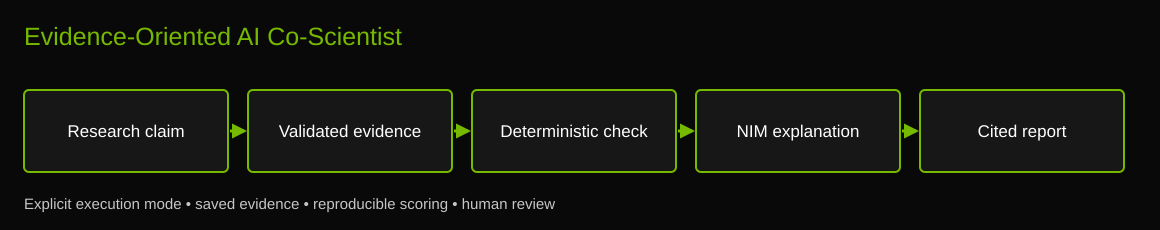

In [2]:
from IPython.display import SVG, display
display(SVG(filename="assets/overview.svg"))

In [3]:
subprocess.run([sys.executable, "-m", "project_demo", "demo", "--mode", "fixture", "--output-dir", "runs/evaluation-tutorial"], check=True)
import json
latest = json.loads(pathlib.Path("runs/evaluation-tutorial/latest.json").read_text())
saved = str(pathlib.Path(latest["run"]) / "result.json")
subprocess.run([sys.executable, "-m", "project_demo", "evaluate", "--results", saved, "--output-dir", "runs/rescore"], check=True)


CompletedProcess(args=['[workspace]\\work\\agent-finance-venv\\Scripts\\python.exe', '-m', 'project_demo', 'evaluate', '--results', '[workspace]\\outputs\\nvidia-repos\\ai-coscientist-nvidia\\runs\\evaluation-tutorial\\20261116T093225-c6182851\\result.json', '--output-dir', 'runs/rescore'], returncode=0)

## Evaluate your live output

Replace `saved` with a recorded live result. Keep the same scoring rules. For agent projects, the playbook also shows remote Helix scoring. No model is called during rescoring. Record remaining human-review questions separately from automatic metrics.

In [4]:
import ipywidgets as widgets
from IPython.display import display
saved_path = widgets.Text(value=saved, description="Result path", layout=widgets.Layout(width="95%"))
display(saved_path)


Text(value='[workspace]\\outputs\\nvidia-repos\\ai-coscientist-nvi…

In [5]:
subprocess.run([sys.executable, "-m", "project_demo", "evaluate", "--results", saved_path.value, "--output-dir", "runs/selected-rescore"], check=True)
display(json.loads(pathlib.Path(saved_path.value).read_text(encoding="utf-8")))


{'command': 'demo',
 'mode': 'fixture',
 'status': 'succeeded',
 'config': {'project': 'ai-coscientist',
  'data': '../data/scenarios.json',
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'max_requests': 12},
 'config_sha256': '45a5bdeec8621309065e81548b9212f183587eee37aec3e4742e7d8199d06a8e',
 'started_at': '2026-11-16T09:32:25.582297+00:00',
 'python': '3.12.14',
 'result': {'scenarios': [{'id': 'matching-results',
    'expected_status': 'supported',
    'check': {'status': 'supported',
     'value': 11.0,
     'citations': ['baseline', 'candidate'],
     'reason': 'Computed (candidate correct/total - baseline correct/total) × 100.',
     'evidence_chain': [{'id': 'baseline',
       'sha256': 'de39652793ed784b9a6f3a0c2ef24e90a6e23cc7b27acf752c4c11e83f79076d',
       'artifact': {'correct': 80,
        'total': 100,
        'evaluation_set_sha256': 'demo-heldout-v1'}},
      {'id': 'candidate',
       'sha256': '47e7e331d8e6c